<a href="https://colab.research.google.com/github/muruganharish123/Epurchase-prediction/blob/main/Ecommerce_purchasepredictionproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


df = pd.read_csv("online_shoppers_intention.csv")



In [ ]:
# Dataset Overview
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())




Dataset shape: (12330, 18)

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

First 5 rows:
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3   


Revenue counts:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Revenue percentage:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


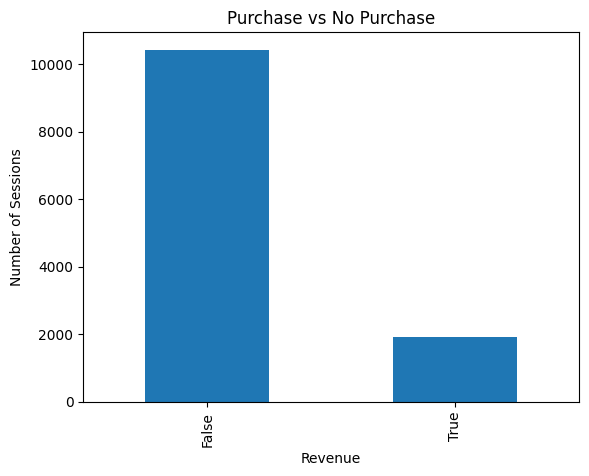

In [ ]:
# Target Variable Analysis
print("\nRevenue counts:")
print(df["Revenue"].value_counts())

print("\nRevenue percentage:")
print(df["Revenue"].value_counts(normalize=True) * 100)

df["Revenue"].value_counts().plot(kind="bar")
plt.title("Purchase vs No Purchase")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")
plt.show()


Numerical Feature Summary:
       Administrative  Administrative_Duration  Informational  \
count    12330.000000             12330.000000   12330.000000   
mean         2.315166                80.818611       0.503569   
std          3.321784               176.779107       1.270156   
min          0.000000                 0.000000       0.000000   
25%          0.000000                 0.000000       0.000000   
50%          1.000000                 7.500000       0.000000   
75%          4.000000                93.256250       0.000000   
max         27.000000              3398.750000      24.000000   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
count            12330.000000    12330.000000             12330.000000   
mean                34.472398       31.731468              1194.746220   
std                140.749294       44.475503              1913.669288   
min                  0.000000        0.000000                 0.000000   
25%             

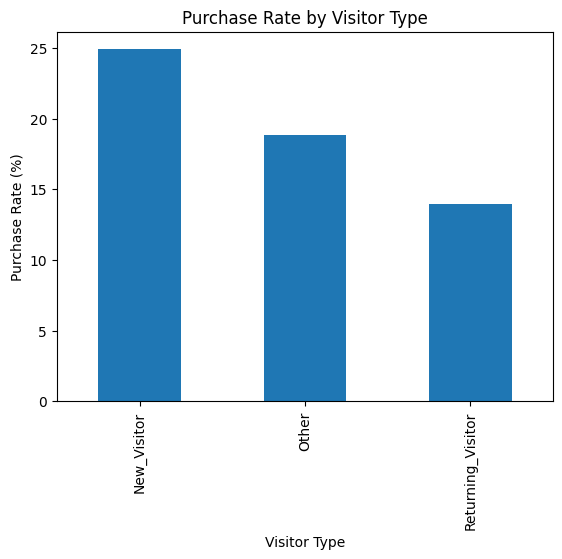


Purchase Rate by Weekend:
Weekend
False    14.891144
True     17.398884
Name: Revenue, dtype: float64


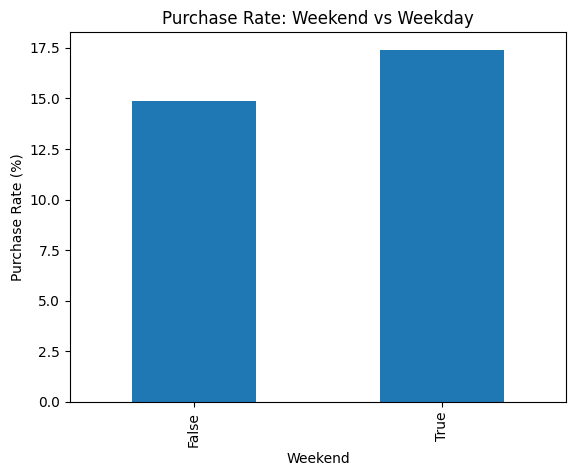


Purchase Rate by Month:
Month
Aug     17.551963
Dec     12.507238
Feb      1.630435
Jul     15.277778
June    10.069444
Mar     10.068170
May     10.850178
Nov     25.350233
Oct     20.947177
Sep     19.196429
Name: Revenue, dtype: float64


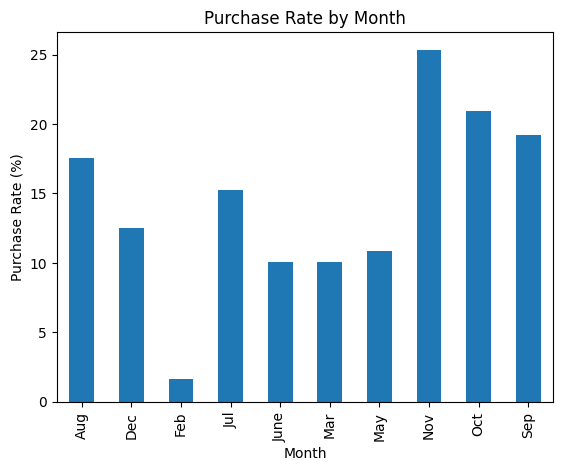


Average Product-Related Pages:
Revenue
False    28.714642
True     48.210168
Name: ProductRelated, dtype: float64


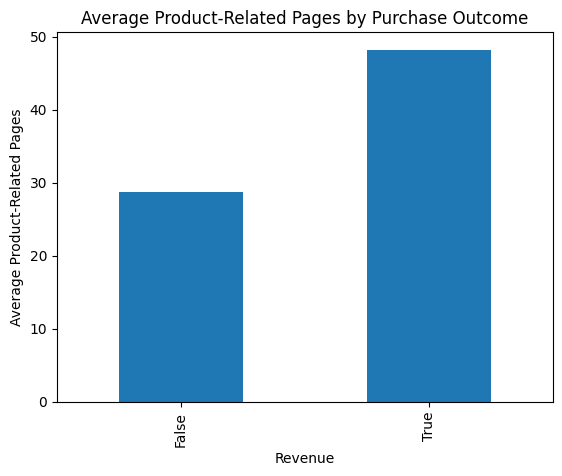


Average Product-Related Browsing Time:
Revenue
False    1069.987809
True     1876.209615
Name: ProductRelated_Duration, dtype: float64


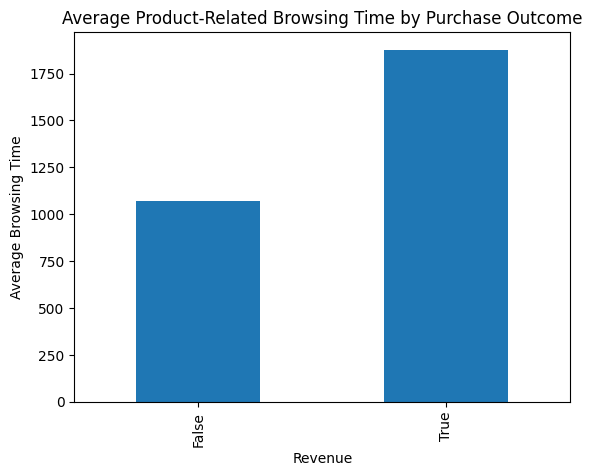


Average Bounce Rate:
Revenue
False    0.025317
True     0.005117
Name: BounceRates, dtype: float64


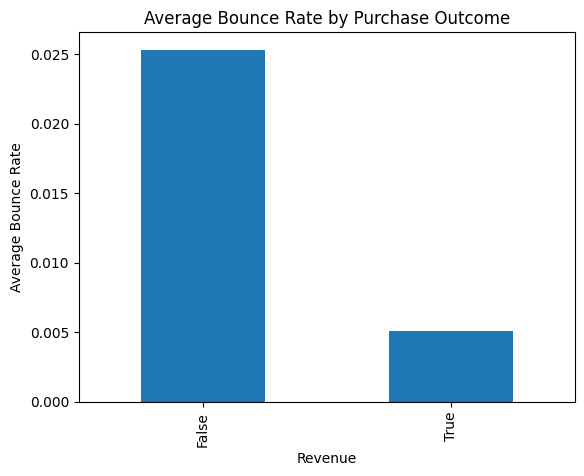

In [ ]:
# Exploratory Data Analysis
print("\nNumerical Feature Summary:")
print(df.describe())


visitor_purchase_rate = df.groupby("VisitorType")["Revenue"].mean() * 100
print("\nPurchase Rate by Visitor Type:")
print(visitor_purchase_rate)

visitor_purchase_rate.plot(kind="bar")
plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Purchase Rate (%)")
plt.show()


weekend_purchase_rate = df.groupby("Weekend")["Revenue"].mean() * 100
print("\nPurchase Rate by Weekend:")
print(weekend_purchase_rate)

weekend_purchase_rate.plot(kind="bar")
plt.title("Purchase Rate: Weekend vs Weekday")
plt.xlabel("Weekend")
plt.ylabel("Purchase Rate (%)")
plt.show()


monthly_purchase_rate = df.groupby("Month")["Revenue"].mean() * 100
print("\nPurchase Rate by Month:")
print(monthly_purchase_rate)

monthly_purchase_rate.plot(kind="bar")
plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate (%)")
plt.show()


product_pages = df.groupby("Revenue")["ProductRelated"].mean()
print("\nAverage Product-Related Pages:")
print(product_pages)

product_pages.plot(kind="bar")
plt.title("Average Product-Related Pages by Purchase Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Product-Related Pages")
plt.show()


product_time = df.groupby("Revenue")["ProductRelated_Duration"].mean()
print("\nAverage Product-Related Browsing Time:")
print(product_time)

product_time.plot(kind="bar")
plt.title("Average Product-Related Browsing Time by Purchase Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Browsing Time")
plt.show()


bounce_rate = df.groupby("Revenue")["BounceRates"].mean()
print("\nAverage Bounce Rate:")
print(bounce_rate)

bounce_rate.plot(kind="bar")
plt.title("Average Bounce Rate by Purchase Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Bounce Rate")
plt.show()


Correlation with Revenue:
Revenue                    1.000000
PageValues                 0.492569
ProductRelated             0.158538
ProductRelated_Duration    0.152373
Administrative             0.138917
Informational              0.095200
Administrative_Duration    0.093587
Informational_Duration     0.070345
Weekend                    0.029295
Browser                    0.023984
TrafficType               -0.005113
Region                    -0.011595
OperatingSystems          -0.014668
SpecialDay                -0.082305
BounceRates               -0.150673
ExitRates                 -0.207071
Name: Revenue, dtype: float64


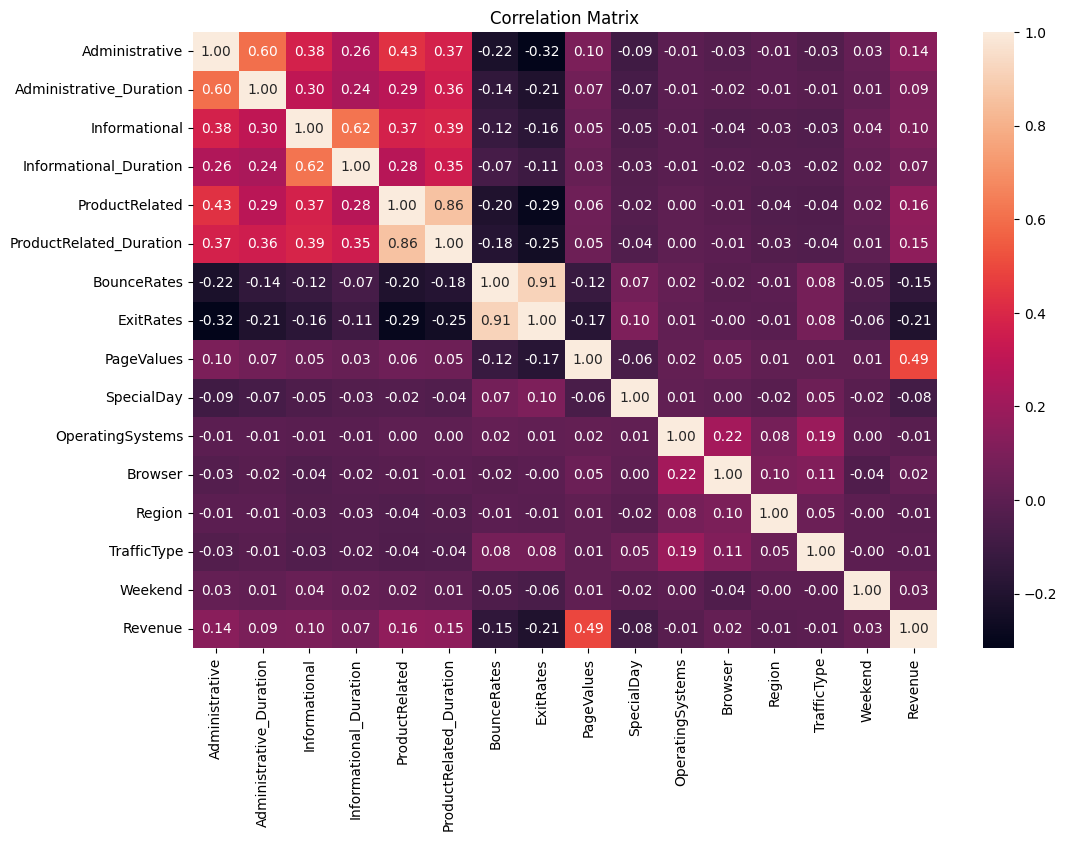

In [ ]:
# Correlation Analysis
correlation_matrix = df.corr(numeric_only=True)

print("\nCorrelation with Revenue:")
print(correlation_matrix["Revenue"].sort_values(ascending=False))

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
# PageValues Investigation
print("\nPageValues by Revenue:")
print(df.groupby("Revenue")["PageValues"].mean())

print("\nPageValues for Purchase Sessions:")
print(df[df["Revenue"] == True]["PageValues"].describe())

print("\nPageValues for Non-Purchase Sessions:")
print(df[df["Revenue"] == False]["PageValues"].describe())



PageValues by Revenue:
Revenue
False     1.975998
True     27.264518
Name: PageValues, dtype: float64

PageValues for Purchase Sessions:
count    1908.000000
mean       27.264518
std        35.191954
min         0.000000
25%         3.641144
50%        16.758134
75%        38.897742
max       361.763742
Name: PageValues, dtype: float64

PageValues for Non-Purchase Sessions:
count    10422.000000
mean         1.975998
std          9.072424
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        246.758590
Name: PageValues, dtype: float64


In [ ]:
# Data Preprocessing
X = df.drop("Revenue", axis=1)

X = X.drop("PageValues", axis=1)

y = df["Revenue"]


categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "SpecialDay"
]

print("\nCategorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Categorical Features:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Numerical Features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']

Feature shape: (12330, 16)
Target shape: (12330,)


In [ ]:
# Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            StandardScaler(),
            numerical_features
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)



Training shape: (9864, 16)
Testing shape: (2466, 16)


In [ ]:
# Feature Preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (9864, 74)
Processed testing shape: (2466, 74)



Logistic Regression Results:
              precision    recall  f1-score   support

       False       0.93      0.61      0.74      2084
        True       0.26      0.75      0.39       382

    accuracy                           0.63      2466
   macro avg       0.59      0.68      0.56      2466
weighted avg       0.83      0.63      0.68      2466

Accuracy: 0.629764801297648
Purchase Precision: 0.25929283771532186
Purchase Recall: 0.7486910994764397
Purchase F1: 0.3851851851851852


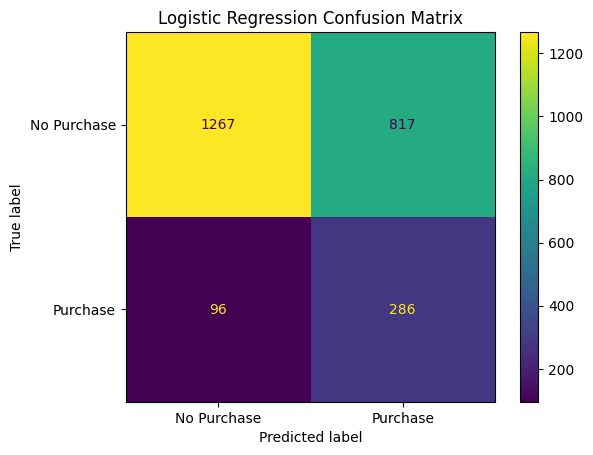

In [ ]:
# Logistic Regression
log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="liblinear"
)

log_model.fit(X_train_processed, y_train)

log_pred = log_model.predict(X_test_processed)

print("\nLogistic Regression Results:")
print(classification_report(y_test, log_pred))

print("Accuracy:", accuracy_score(y_test, log_pred))
print("Purchase Precision:", precision_score(y_test, log_pred))
print("Purchase Recall:", recall_score(y_test, log_pred))
print("Purchase F1:", f1_score(y_test, log_pred))


# Logistic Regression Confusion Matrix
log_cm = confusion_matrix(y_test, log_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=log_cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()


Random Forest Results:
              precision    recall  f1-score   support

       False       0.86      0.98      0.92      2084
        True       0.54      0.10      0.16       382

    accuracy                           0.85      2466
   macro avg       0.70      0.54      0.54      2466
weighted avg       0.81      0.85      0.80      2466

Accuracy: 0.8471208434712084
Purchase Precision: 0.5362318840579711
Purchase Recall: 0.0968586387434555
Purchase F1: 0.164079822616408


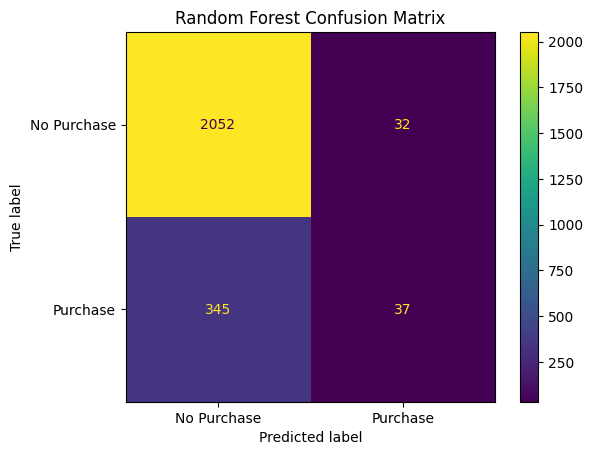


Model Comparison

Logistic Regression
Accuracy: 0.629764801297648
Purchase Precision: 0.25929283771532186
Purchase Recall: 0.7486910994764397
Purchase F1: 0.3851851851851852

Random Forest
Accuracy: 0.8471208434712084
Purchase Precision: 0.5362318840579711
Purchase Recall: 0.0968586387434555
Purchase F1: 0.164079822616408


In [ ]:
# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

print("\nRandom Forest Results:")
print(classification_report(y_test, rf_pred))

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Purchase Precision:", precision_score(y_test, rf_pred))
print("Purchase Recall:", recall_score(y_test, rf_pred))
print("Purchase F1:", f1_score(y_test, rf_pred))


# Random Forest Confusion Matrix
rf_cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()


# Model Comparison
print("\nModel Comparison")

print("\nLogistic Regression")
print("Accuracy:", accuracy_score(y_test, log_pred))
print("Purchase Precision:", precision_score(y_test, log_pred))
print("Purchase Recall:", recall_score(y_test, log_pred))
print("Purchase F1:", f1_score(y_test, log_pred))


print("\nRandom Forest")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Purchase Precision:", precision_score(y_test, rf_pred))
print("Purchase Recall:", recall_score(y_test, rf_pred))
print("Purchase F1:", f1_score(y_test, rf_pred))


Top 15 Features:
num__ExitRates                  0.140194
num__ProductRelated_Duration    0.127722
num__ProductRelated             0.103530
num__BounceRates                0.076211
num__Administrative_Duration    0.075498
num__Administrative             0.054861
num__Informational_Duration     0.028261
cat__Month_Nov                  0.022504
num__Informational              0.021939
cat__TrafficType_2              0.016759
cat__Region_1                   0.015204
cat__Region_3                   0.013090
cat__Browser_2                  0.011943
cat__OperatingSystems_2         0.011813
cat__Month_May                  0.011800
dtype: float64


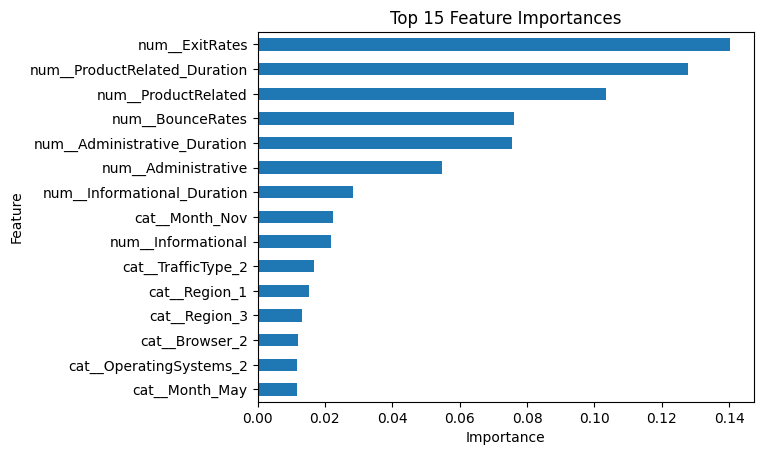

In [ ]:
# Feature Importance

feature_names = preprocessor.get_feature_names_out()

importances = rf_model.feature_importances_

feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

print("\nTop 15 Features:")
print(feature_importance.head(15))

feature_importance.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [ ]:
final_threshold = 0.5

for i in range(10):

    sample = X_test.iloc[[i]]

    sample_processed = preprocessor.transform(sample)

    prediction_probability = log_model.predict_proba(sample_processed)[0][1]

    prediction = prediction_probability >= final_threshold

    print("Sample:", i)
    print("Purchase probability:", prediction_probability)
    print("Predicted purchase:", prediction)
    print("------------------------")

Sample: 0
Purchase probability: 0.16342006660484182
Predicted purchase: False
------------------------
Sample: 1
Purchase probability: 0.31215626447718314
Predicted purchase: False
------------------------
Sample: 2
Purchase probability: 0.6126998392435673
Predicted purchase: True
------------------------
Sample: 3
Purchase probability: 0.024440633760309298
Predicted purchase: False
------------------------
Sample: 4
Purchase probability: 0.10466823467476528
Predicted purchase: False
------------------------
Sample: 5
Purchase probability: 0.19967619476983084
Predicted purchase: False
------------------------
Sample: 6
Purchase probability: 0.41531817557197565
Predicted purchase: False
------------------------
Sample: 7
Purchase probability: 0.6903223118950502
Predicted purchase: True
------------------------
Sample: 8
Purchase probability: 0.7206963354380851
Predicted purchase: True
------------------------
Sample: 9
Purchase probability: 0.5241064813791773
Predicted purchase: True
--